In [1]:
#load files
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/1987 - 2022.csv")
df.head()

,Title,Seasons,Episodes,Country,Premiere Year,Final Year,Original Channel,Technique
0,¡Mucha Lucha!,3,52,United States,2002,2005,Kids' WB,Flash
1,10+2,1,52,Spain,1994,1994,"Televisió de Catalunya, KiKa",Traditional
2,100% Wolf: Legend of the Moonstone,2,26,Australia,2020,Present,ABC Me,CGI
3,1001 Nights,2,52,Canada,2011,2012,Teletoon,Flash
4,101 Dalmatian Street,1,40,"United Kingdom, Canada",2019,2020,"Disney Channel, Disney+",Toon Boom Harmony


In [5]:
print(df.shape)
df.info()

(2477, 8)
<class 'pandas.DataFrame'>
RangeIndex: 2477 entries, 0 to 2476
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Title             2477 non-null   str  
 1   Seasons           1778 non-null   str  
 2   Episodes          2440 non-null   str  
 3   Country           2477 non-null   str  
 4   Premiere Year     2477 non-null   int64
 5   Final Year        2477 non-null   str  
 6   Original Channel  2422 non-null   str  
 7   Technique         2472 non-null   str  
dtypes: int64(1), str(7)
memory usage: 154.9 KB


In [6]:
print(df["Premiere Year"].min(), df["Premiere Year"].max())
df.isnull().sum()

1987 2022


Title                 0
Seasons             699
Episodes             37
Country               0
Premiere Year         0
Final Year            0
Original Channel     55
Technique             5
dtype: int64

In [3]:
# clearning: seasons, episodes and final year were stored as text.
# converting them to numbers. Anything that isn't a number (like "Present")
df["Seasons"] = pd.to_numeric(df["Seasons"], errors="coerce")
df["Episodes"] = pd.to_numeric(df["Episodes"], errors="coerce")
df["Final Year"] = pd.to_numeric(df["Final Year"], errors="coerce")

# new columns
df["Episodes per Season"] = df["Episodes"] / df["Seasons"]
df["Years Run"] = df["Final Year"] - df["Premiere Year"]

df.head()

,Title,Seasons,Episodes,Country,Premiere Year,Final Year,Original Channel,Technique,Episodes per Season,Years Run
0,¡Mucha Lucha!,3.0,52.0,United States,2002,2005.0,Kids' WB,Flash,17.333333,3.0
1,10+2,1.0,52.0,Spain,1994,1994.0,"Televisió de Catalunya, KiKa",Traditional,52.000000,0.0
2,100% Wolf: Legend of the Moonstone,2.0,26.0,Australia,2020,NaN,ABC Me,CGI,13.000000,NaN
3,1001 Nights,2.0,52.0,Canada,2011,2012.0,Teletoon,Flash,26.000000,1.0
4,101 Dalmatian Street,1.0,40.0,"United Kingdom, Canada",2019,2020.0,"Disney Channel, Disney+",Toon Boom Harmony,40.000000,1.0


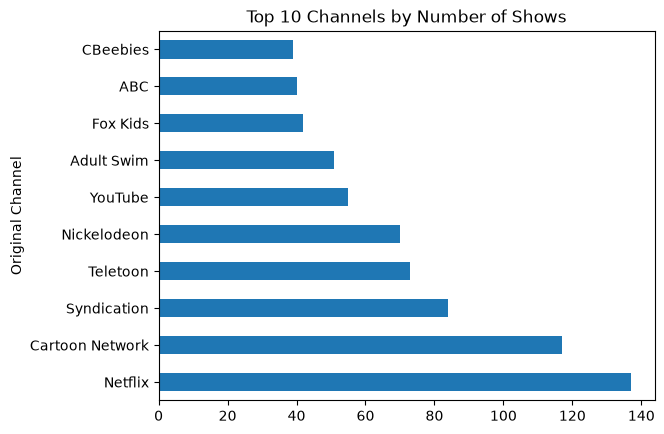

In [45]:
# Q1: Which channels have the most shows?
df["Original Channel"].value_counts().head(10)

# Bar chart of the same thing
df["Original Channel"].value_counts().head(10).plot(kind="barh")
plt.title("Top 10 Channels by Number of Shows")
plt.show()

# FINDINGS: Which channels have the most shows?
# -Netflix has the most shows (about 137), followed by Cartoon Network (about 117) and Syndication (about 84).

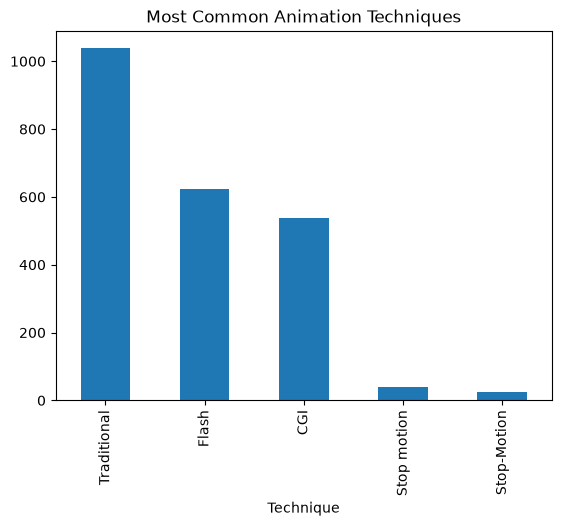

In [47]:
# Q2: what are the most common animation technique?

df["Technique"].value_counts().head(10)
df["Technique"].value_counts().head(5).plot(kind="bar")
plt.title("Most Common Animation Techniques")
plt.show()

# traditional is the most commen technique

In [46]:
# Q3: Did technique change over time?
# Turn each premiere year into a decade (1994 -> 1990)
df["Decade"] = (df["Premiere Year"] // 10) * 10

# Keep only the 4 most common techniques so the table is clear
top_techniques = df["Technique"].value_counts().head(4).index
subset = df[df["Technique"].isin(top_techniques)]

# crosstab counts shows for each decade and technique
table = pd.crosstab(subset["Decade"], subset["Technique"])
table

# Findings:
# YES. Traditional animation dominated early on: 87 of 87 shows in the 1980s and 452 of 474 shows (about 95%) in the 1990s.
# - Traditional dropped sharply after that: 291 shows in the 2000s, 145 in the
#   2010s, and 63 in the 2020s (about 22% of shows).
# - Flash rose fastest: 3 shows in the 1990s, 200 in the 2000s, and 316 in the 2010s,
#   making it the most common technique in the 2010s (about 43% of shows).
# - CGI grew steadily: 18 shows in the 1990s, 133 in the 2000s, 266 in the 2010s.
#   In the 2020s CGI is the most common (120 shows, about 42%), just ahead of Flash (104).
# - Stop motion stayed small in every decade (never more than 27 shows).

Technique,CGI,Flash,Stop motion,Traditional
Decade,,,,
1980,0,0,0,87
1990,18,3,1,452
2000,133,200,27,291
2010,266,316,10,145
2020,120,104,0,63


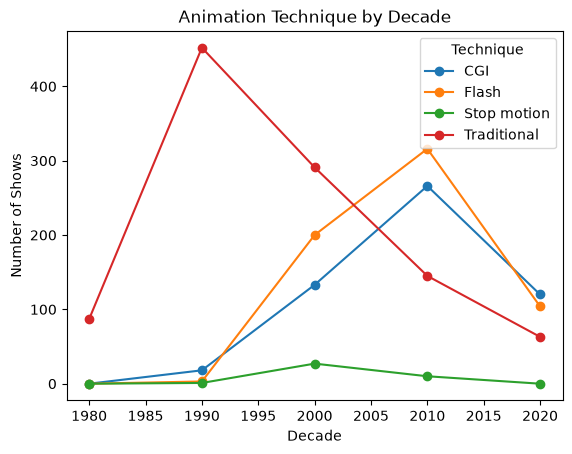

In [10]:

table.plot(kind="line", marker="o")
plt.title("Animation Technique by Decade")
plt.ylabel("Number of Shows")
plt.show()

In [15]:
#Q4: Episodes per season and years run by country
# Use the 10 countries with the most shows, so averages aren't based on 1 or 2 shows
top_countries = df["Country"].value_counts().head(10).index
subset = df[df["Country"].isin(top_countries)]

# groupby: split the shows by country, then average each group
summary = subset.groupby("Country")[["Episodes per Season", "Years Run"]].mean()
summary.round(1)


,Episodes per Season,Years Run
Country,,
Australia,27.1,1.5
Brazil,20.6,1.9
Britain,25.1,2.3
Canada,21.1,2.2
"Canada, France",28.1,1.9
"Canada, United States",22.9,2.4
France,39.4,1.7
UK,19.1,1.6
US,21.0,2.0


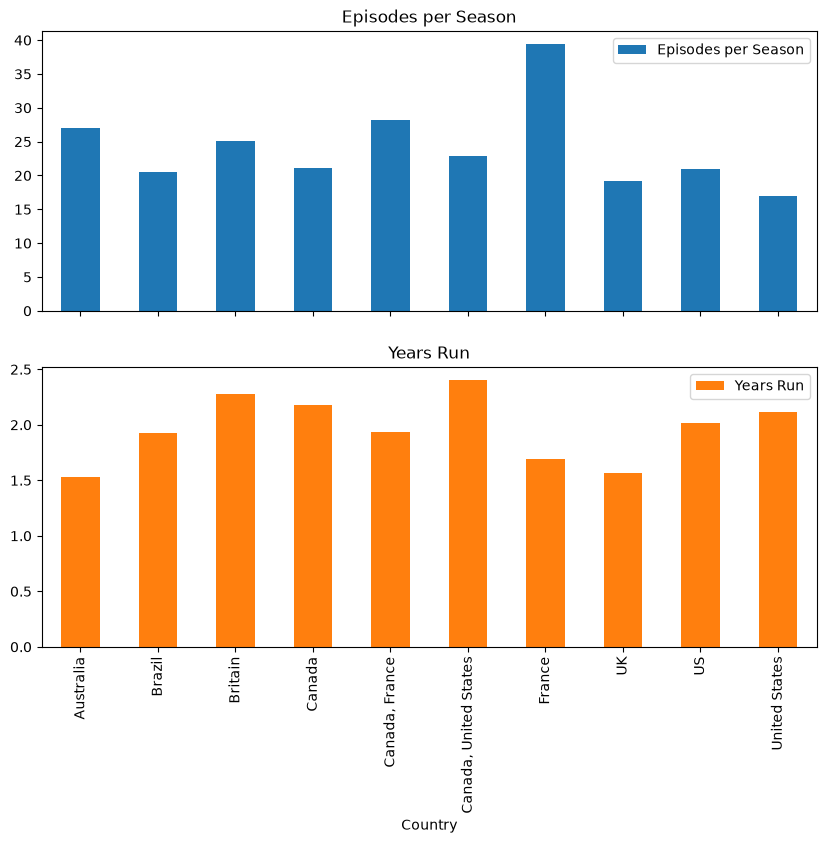

In [18]:
# Median is less affected by a few very long shows, so check it too
subset.groupby("Country")[["Episodes per Season", "Years Run"]].median()
summary.plot(kind="bar", subplots=True, figsize=(10, 8))
plt.show()

In [38]:
# The same country appears under different names
df["Country"] = (
    df["Country"]
    .str.replace(r"\bUS\b", "United States", regex=True)
    .str.replace(r"\bUK\b", "United Kingdom", regex=True)
    .str.replace(r"\bBritain\b", "United Kingdom", regex=True)
)

df["Country"].value_counts().head(15)

Country
United States                    1019
United Kingdom                    209
Canada                            206
Canada, United States             134
France                            123
Canada, France                     49
Australia                          43
Brazil                             42
South Korea                        30
United States, Canada              29
Spain                              25
Italy                              25
France, United States              24
United Kingdom, United States      22
China                              18
Name: count, dtype: int64

In [32]:
# Q4: Episodes per season and years run by country
top_countries = df["Country"].value_counts().head(10).index
subset = df[df["Country"].isin(top_countries)]

In [33]:
summary = subset.groupby("Country")[["Episodes per Season", "Years Run"]].mean()
summary["Number of Shows"] = subset.groupby("Country")["Title"].count()
summary.round(1)

,Episodes per Season,Years Run,Number of Shows
Country,,,
Australia,27.1,1.5,43
Brazil,20.6,1.9,42
Canada,21.1,2.2,206
"Canada, France",28.1,1.9,49
"Canada, United States",21.6,2.5,134
France,39.4,1.7,123
South Korea,28.2,3.0,30
United Kingdom,21.7,1.9,209
United States,18.4,2.1,1019


In [42]:
# Keep only shows made in ONE country (no comma in the Country text)
single = df[~df["Country"].str.contains(",")]

# Top 10 single countries by number of shows
top_countries = single["Country"].value_counts().head(10).index
subset = single[single["Country"].isin(top_countries)]

summary = subset.groupby("Country")[["Episodes per Season", "Years Run"]].mean()
summary["Number of Shows"] = subset.groupby("Country")["Title"].count()
summary.round(1)

,Episodes per Season,Years Run,Number of Shows
Country,,,
Australia,27.1,1.5,43
Brazil,20.6,1.9,42
Canada,21.1,2.2,206
China,407.2,1.3,18
France,39.4,1.7,123
Italy,36.4,1.4,25
South Korea,28.2,3.0,30
Spain,38.3,1.2,25
United Kingdom,21.7,1.9,209


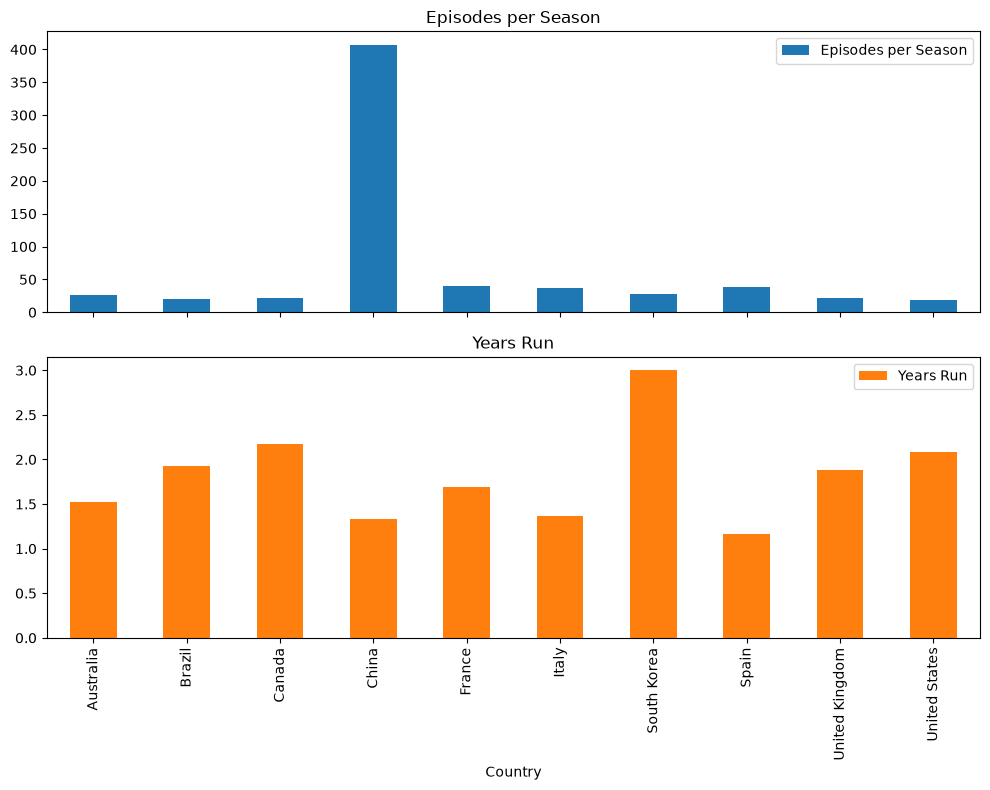

In [48]:
summary[["Episodes per Season", "Years Run"]].plot(kind="bar", subplots=True, figsize=(10, 8))
plt.tight_layout()
plt.show()

# Q4 FINDINGS: Episodes per season and years run by country
# (Top 10 country groups; US/UK/Britain merged; co-productions kept as their own groups)

# EPISODES PER SEASON:
# - France is highest (avg 39.4, median 33, 123 shows), a consistent pattern.
# - The United States is lowest by median (13, 1,019 shows); the UK is also low (median 15).

# YEARS RUN:
# - Median is 1 year for almost every group, so most shows run about a year.
# - Averages are 1.5 to 3.0 years because a few long-running shows pull them up.
# - South Korea is longest (avg 3.0) but has only 30 shows, so it is less reliable.
# - Differences between countries are small.

# LIMITATIONS:
# - Shows still running ("Present") are excluded from Years Run, so durations look shorter.
# - 699 shows have no Seasons value and are excluded from Episodes per Season.
# - Co-productions are separate groups, and small groups (under about 30 shows) are less reliable.

In [49]:
subset[subset["Country"] == "China"].sort_values("Episodes per Season", ascending=False)[["Title", "Seasons", "Episodes", "Episodes per Season"]].head(5)


,Title,Seasons,Episodes,Episodes per Season
12,3000 Whys of Blue Cat,1.0,3057.0,3057.0
1276,Music Up,1.0,52.0,52.0
501,Deer Squad,1.0,40.0,40.0
1657,Screechers Wild!,2.0,62.0,31.0
939,Journey to the West – Legends of the Monkey King,1.0,26.0,26.0


In [50]:
subset.groupby("Country")[["Episodes per Season", "Years Run"]].median()

,Episodes per Season,Years Run
Country,,
Argentina,13.250000,0.0
Australia,26.000000,1.0
"Australia, Brazil",52.000000,3.0
"Australia, Canada",18.666667,1.0
"Australia, Canada, United States",NaN,1.0
...,...,...
"United States, United Kingdom",16.250000,3.0
"United States, United Kingdom, Australia",13.000000,0.0
Vietman,NaN,0.0
